(200, 5)
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


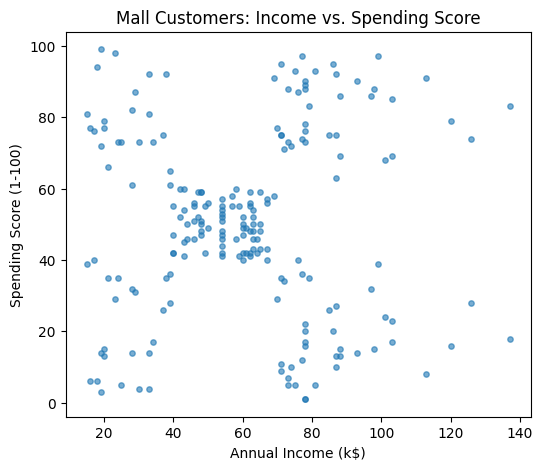

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "/kaggle/input/datasets/abdulsami324243/mallcustomer/Mall_Customers.csv"
df = pd.read_csv(DATA_PATH)
print(df.shape)
print(df.columns.tolist())
print(df.head())

plt.figure(figsize=(6, 5))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], s=15, alpha=0.6)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Mall Customers: Income vs. Spending Score")
plt.show()

In [2]:
from sklearn.preprocessing import StandardScaler

X = df[["Annual Income (k$)", "Spending Score (1-100)"]].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled[:5])

[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


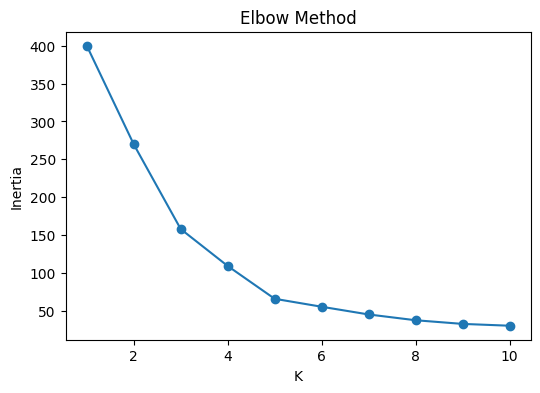

In [3]:
from sklearn.cluster import KMeans

inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [4]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans.fit(X_scaled)

df["Cluster"] = kmeans.predict(X_scaled)
print(df["Cluster"].value_counts())

Cluster
0    81
1    39
3    35
4    23
2    22
Name: count, dtype: int64


In [5]:
from sklearn.metrics import silhouette_score

print(f"Silhouette Score (K=5): {silhouette_score(X_scaled, df['Cluster']):.3f}")

km3 = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
print(f"Silhouette Score (K=3): {silhouette_score(X_scaled, km3.labels_):.3f}")

km7 = KMeans(n_clusters=7, random_state=42, n_init=10).fit(X_scaled)
print(f"Silhouette Score (K=7): {silhouette_score(X_scaled, km7.labels_):.3f}")

Silhouette Score (K=5): 0.555
Silhouette Score (K=3): 0.467
Silhouette Score (K=7): 0.528


(200, 5)
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


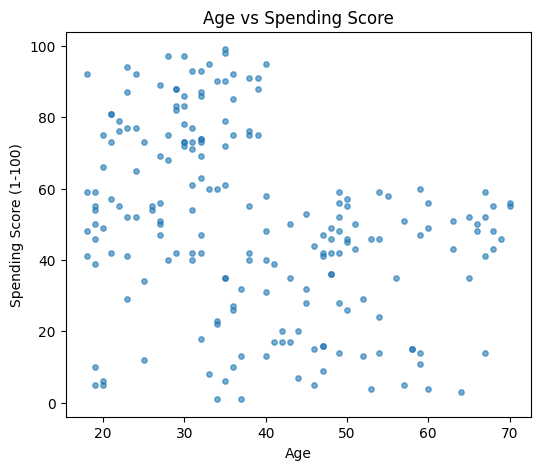

Cluster
1    54
4    47
2    40
3    39
0    20
Name: count, dtype: int64
Silhouette Score: 0.417
               Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                       
0        46.250000           26.750000               18.350000
1        25.185185           41.092593               62.240741
2        32.875000           86.100000               81.525000
3        39.871795           86.102564               19.358974
4        55.638298           54.382979               48.851064


In [6]:
# ============================================================
# TASK 1 — Mall Customer Segmentation
# ============================================================

# ---------- STAGE 1: DATASET LOADING ----------
import pandas as pd
DATA_PATH = "/kaggle/input/datasets/abdulsami324243/mallcustomer/Mall_Customers.csv"
df = pd.read_csv(DATA_PATH)
print(df.shape)
print(df.columns.tolist())

# ---------- STAGE 2: VISUALIZATION ----------
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 5))
plt.scatter(df["Age"], df["Spending Score (1-100)"], s=15, alpha=0.6)
plt.xlabel("Age")
plt.ylabel("Spending Score (1-100)")
plt.title("Age vs Spending Score")
plt.show()

# ---------- STAGE 3: PREPROCESSING ----------
from sklearn.preprocessing import StandardScaler
feature_cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X_scaled = StandardScaler().fit_transform(df[feature_cols].values)

# ---------- STAGE 4: TRAINING ----------
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans.fit(X_scaled)

# ---------- STAGE 5: TESTING ----------
df["Cluster"] = kmeans.predict(X_scaled)
print(df["Cluster"].value_counts())

# ---------- STAGE 6: VALIDATION ----------
from sklearn.metrics import silhouette_score
print("Silhouette Score:", round(silhouette_score(X_scaled, df["Cluster"]), 3))
print(df.groupby("Cluster")[feature_cols].mean())